# About the assignment

The task is to build a model that predicts whether a person earns more than $50,000 a year based on their demographic data. In this assignment you will learn to ensemble base models with bagging and stacking to solve a classification problem. We are interested in how well different models estimate probabilities, so the target metric is AUC-ROC.

Points are awarded for individual tasks. It is recommended to solve them in the order in which they are given.


<font color='OrangeRed'>**Note!**</font> A hyperparameter search with GridSearchCV can take a long time, usually up to <font color='CornflowerBlue'>**10–15 minutes**</font>

--------

In this assignment you will work with a census dataset that includes information about people's income (more or less than $50k).

[Dataset description](https://archive.ics.uci.edu/dataset/2/adult)

Before we start, let's import some modules and load the data.

In [27]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
tmp = fetch_ucirepo(id=2)


In [3]:
adult = tmp
# data (as pandas dataframes)
X = adult.data.features
y = adult.data.targets

adult.variables

,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,N/A,None,no
1,workclass,Feature,Categorical,Income,"Private, Self-emp-not-inc, Self-emp-inc, Feder...",None,yes
2,fnlwgt,Feature,Integer,None,None,None,no
3,education,Feature,Categorical,Education Level,"Bachelors, Some-college, 11th, HS-grad, Prof-...",None,no
4,education-num,Feature,Integer,Education Level,None,None,no
5,marital-status,Feature,Categorical,Other,"Married-civ-spouse, Divorced, Never-married, S...",None,no
6,occupation,Feature,Categorical,Other,"Tech-support, Craft-repair, Other-service, Sal...",None,yes
7,relationship,Feature,Categorical,Other,"Wife, Own-child, Husband, Not-in-family, Other...",None,no
8,race,Feature,Categorical,Race,"White, Asian-Pac-Islander, Amer-Indian-Eskimo,...",None,no
9,sex,Feature,Binary,Sex,"Female, Male.",None,no


In [4]:
y.value_counts()

income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64

##  <font color='DarkOrange'>**Task 1 [2 points]**</font>

Data preparation

Load the dataset and preprocess it:
1. Bring the target variable to a single format:
    - 0 — income less than or equal to $50k
    - 1 — income greater than $50k
2.  Split the whole dataset into `train/test` in an `80/20` ratio with `random_state=42`
    * Reset the indices of `X_train`, `X_test`, `y_train`, `y_test` with `df.reset_index(drop=True)`
2. Make two versions of the dataset from this split. For the first version:
- do not handle missing values in the categorical features (keep the `NaN`s)
- convert the `categorical variables` into numeric ones with a [One-Hot Encoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) (handle_unknown='ignore' will help)
- after encoding, restore the `NaN`s in the corresponding rows if they were present in the original data.

3. For the second version, process the `categorical variables:`
- handle missing values by replacing them with `"Other"`
- merge rare classes into `"Other"`
- then convert the `categorical variables` into numeric ones with a [One-Hot Encoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)

In [5]:
y['income'].apply(lambda x: 1 if x == '>50K' or x == '>50K.' else 0).value_counts()

income
0    37155
1    11687
Name: count, dtype: int64

In [6]:
# замена целевой переменной
y['income'] = y['income'].apply(lambda x: 1 if x == '>50K' or x == '>50K.' else 0)

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# сплит на трейн и тест
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
for df in [X_train, X_test, y_train, y_test]:
    df.reset_index(drop=True, inplace=True)

# ищем категориальные
categorical_columns = X_train.select_dtypes(include=['object']).columns

In [8]:
import numpy as np
nan_count = X.isna().sum()
print("Number of NaNs in each column:\n", nan_count)

Number of NaNs in each column:
 age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
dtype: int64


In [9]:
# Первая версия
X_train_1 = X_train.copy()
X_test_1 = X_test.copy()

ohe = OneHotEncoder(handle_unknown='ignore')

X_train_1 = ohe.fit_transform(X_train_1[categorical_columns])
X_test_1 = ohe.transform(X_test_1[categorical_columns])

In [10]:
for col in categorical_columns:
    value_counts = X_train[col].value_counts(normalize=True)
    print(value_counts)

workclass
Private             0.709564
Self-emp-not-inc    0.079215
Local-gov           0.065507
State-gov           0.041644
?                   0.037858
Self-emp-inc        0.035978
Federal-gov         0.029555
Without-pay         0.000444
Never-worked        0.000235
Name: proportion, dtype: float64
education
HS-grad         0.324034
Some-college    0.222532
Bachelors       0.164333
Masters         0.054872
Assoc-voc       0.041666
11th            0.036854
Assoc-acdm      0.032478
10th            0.029586
7th-8th         0.018913
Prof-school     0.016687
9th             0.015586
12th            0.013488
Doctorate       0.012106
5th-6th         0.010391
1st-4th         0.004837
Preschool       0.001638
Name: proportion, dtype: float64
marital-status
Married-civ-spouse       0.458347
Never-married            0.330510
Divorced                 0.135567
Separated                0.031966
Widowed                  0.030405
Married-spouse-absent    0.012464
Married-AF-spouse        0.000742


In [11]:
# Вторая версия

# замена пропусков на "Other"
X_train_2 = X_train.copy()
X_test_2 = X_test.copy()
X_train_2[categorical_columns] = X_train_2[categorical_columns].fillna("Other")
X_test_2[categorical_columns] = X_test_2[categorical_columns].fillna("Other")

threshold = 0.005  # трешхолд будет 0.5% от данных
rare_classes = {}

# ищем редкие по трэйну
for col in categorical_columns:
    value_counts = X_train_2[col].value_counts(normalize=True)
    rare_classes[col] = value_counts[value_counts < threshold].index.tolist()

# Заменяем
for col in categorical_columns:
    X_train_2[col] = X_train_2[col].apply(lambda x: "Other" if x in rare_classes[col] else x)
    X_test_2[col] = X_test_2[col].apply(lambda x: "Other" if x in rare_classes[col] else x)

ohe = OneHotEncoder(handle_unknown='ignore')

X_train_2 = ohe.fit_transform(X_train_2[categorical_columns])
X_test_2 = ohe.transform(X_test_2[categorical_columns])

 ## <font color='DarkOrange'>**Task 2 [1 point]**</font>
 1. Train a [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) on both versions of the dataset
 2. Use `predict` and `predict_proba` to predict labels and probabilities on the test set
 3. Compare Precision, Recall, F1 and AUC-ROC between the two models. Which model is better: the one where we handled missing values ourselves, or the one that handles them on its own?
 4. Answer the question: how do decision trees estimate probabilities?

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

dtf1 = DecisionTreeClassifier(random_state=42)
dtf2 = DecisionTreeClassifier(random_state=42)

# обучаем
dtf1.fit(X_train_1, y_train)
dtf2.fit(X_train_2, y_train)

# предикты
y_pred_1 = dtf1.predict(X_test_1)
y_pred_2 = dtf2.predict(X_test_2)

# вероятности
y_proba_1 = dtf1.predict_proba(X_test_1)[:, 1]
y_proba_2 = dtf2.predict_proba(X_test_2)[:, 1]

# метрики 1
precision_1 = precision_score(y_test, y_pred_1)
recall_1 = recall_score(y_test, y_pred_1)
f1_1 = f1_score(y_test, y_pred_1)
roc_auc_1 = roc_auc_score(y_test, y_proba_1)

# метрики 2
precision_2 = precision_score(y_test, y_pred_2)
recall_2 = recall_score(y_test, y_pred_2)
f1_2 = f1_score(y_test, y_pred_2)
roc_auc_2 = roc_auc_score(y_test, y_proba_2)

# вывод
print(f"Version 1 - Precision: {precision_1}, Recall: {recall_1}, F1: {f1_1}, AUC-ROC: {roc_auc_1}")
print(f"Version 2 - Precision: {precision_2}, Recall: {recall_2}, F1: {f1_2}, AUC-ROC: {roc_auc_2}")

Version 1 - Precision: 0.6574320724560468, Recall: 0.5239915074309979, F1: 0.5831758034026465, AUC-ROC: 0.8223907887585145
Version 2 - Precision: 0.6602150537634408, Recall: 0.5214437367303609, F1: 0.5826809015421115, AUC-ROC: 0.823553390985208


**Your answer:**
The model where we handled the missing values ourselves performs better, although the first model beats the second one in recall by ~0.026.
Trees estimate probabilities based on the distance from the leaves.

 ## <font color='DarkOrange'>**Task 3 [2 points]**</font>

Build bagging over decision trees

**<font color='DarkOrange'>[0.75 points]</font>** Build bagging with decision trees for the classification task
* Use the processed dataset (from here on we use only this one)
* Use [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html) from sklearn
* Use the default parameters with `random_state=42`.
* Train the ensemble on the training data
* Make predictions on the test set (`predict` and `predict_proba`)
* Print Precision, Recall, F1 and AUC-ROC

In [13]:
from sklearn.ensemble import BaggingClassifier

bagging_clf = BaggingClassifier(random_state=42)

bagging_clf.fit(X_train_2, y_train)

y_pred_bagging = bagging_clf.predict(X_test_2)
y_proba_bagging = bagging_clf.predict_proba(X_test_2)[:, 1]

precision_bagging = precision_score(y_test, y_pred_bagging)
recall_bagging = recall_score(y_test, y_pred_bagging)
f1_bagging = f1_score(y_test, y_pred_bagging)
roc_auc_bagging = roc_auc_score(y_test, y_proba_bagging)

print(f"Bagging - Precision: {precision_bagging}, Recall: {recall_bagging}, F1: {f1_bagging}, AUC-ROC: {roc_auc_bagging}")

Bagging - Precision: 0.6608557844690967, Recall: 0.5312101910828025, F1: 0.5889830508474576, AUC-ROC: 0.8464817236226637


**<font color='DarkOrange'>[0.75 points]</font>** Find the optimal hyperparameters for bagging with [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

Search over the following parameters:
* `n_estimators: [10, 25, 50, 100, 200]`
* `max_features: [0.2, 0.5, 0.7, 1.0]`
* `max_samples: [0.5, 0.75, 1.0]`
* `base_estimator__max_depth: [4, 6, 8, 10, 20, None]` — this parameter tunes the depth of the base estimator (the tree)

Use our custom `score_auc` as the optimization metric for GridSearchCV: pass `scoring='score_auc'` when creating `GridSearchCV()`

In [ ]:
'''from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

def score_auc(estimator, X, y):
    y_score = estimator.predict_proba(X)[:, 1]  # Берем вероятности только для положительного класса (1)
    return roc_auc_score(y, y_score)

param_grid = {
    'n_estimators': [10, 25, 50, 100, 200],
    'max_features': [0.2, 0.5, 0.7, 1.0],
    'max_samples': [0.5, 0.75, 1.0],
    'estimator__max_depth': [4, 6, 8, 10, 20, None]
}

grid_search = GridSearchCV(
    estimator=BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=42),
    param_grid=param_grid,
    scoring=score_auc,
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_2, y_train)

print("Best parameters found: ", grid_search.best_params_)
print("Best AUC-ROC score: ", grid_search.best_score_)'''

'from sklearn.metrics import roc_auc_score\nfrom sklearn.model_selection import GridSearchCV\nfrom sklearn.tree import DecisionTreeClassifier\n\ndef score_auc(estimator, X, y):\n    y_score = estimator.predict_proba(X)[:, 1]  # Берем вероятности только для положительного класса (1)\n    return roc_auc_score(y, y_score)\n\n\n# Define the parameter grid\nparam_grid = {\n    \'n_estimators\': [10, 25, 50, 100, 200],\n    \'max_features\': [0.2, 0.5, 0.7, 1.0],\n    \'max_samples\': [0.5, 0.75, 1.0],\n    \'estimator__max_depth\': [4, 6, 8, 10, 20, None]\n}\n\n# Initialize the GridSearchCV object\ngrid_search = GridSearchCV(\n    estimator=BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=42),\n    param_grid=param_grid,\n    scoring=score_auc,\n    cv=5,\n    n_jobs=-1,\n    verbose=1\n)\n\n# Fit the grid search to the data\ngrid_search.fit(X_train_2, y_train)\n\n# Print the best parameters and the best score\nprint("Best parameters found: ", grid_search.best_params_)\npr

It ran for half an hour, that's unreal.

**<font color='DarkOrange'>[0.25 points]</font>** How does bagging estimate probabilities?

<font color='MediumOrchid'>**Your conclusions:**</font>
It averages the probabilities of all base models.

**<font color='DarkOrange'>[0.25 points]</font>** Train a model with the best parameters.
How much did the quality improve compared with the default parameters?

In [15]:
'''best_params = grid_search.best_params_
model = BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=42, **best_params)
model.fit(X_train_2, y_train)
y_pred = model.predict(X_test)'''

'best_params = grid_search.best_params_\nmodel = BaggingClassifier(estimator=DecisionTreeClassifier(), random_state=42, **best_params)\nmodel.fit(X_train_2, y_train)\ny_pred = model.predict(X_test)'

<font color='MediumOrchid'>**Your conclusions:**</font>

## <font color='DarkOrange'>**Task 4 [4 points]**</font> + <font color='MediumSeaGreen'>**[1 bonus]**</font>

Build stacking

**<font color='DarkOrange'>[1 point]</font>** Build 3 base models
* Logistic regression
* SVM
* Decision tree (with random_state=42)

Evaluate the models:

* Train the models on the whole training set.
* Measure Precision, Recall, F1 and AUC-ROC on the test set

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
lr_model = LogisticRegression(random_state=42)
svm_model = SVC(random_state=42, probability=True)
dt_model = DecisionTreeClassifier(random_state=42)

In [17]:
lr_model.fit(X_train_2, y_train)
svm_model.fit(X_train_2, y_train)
dt_model.fit(X_train_2, y_train)

DecisionTreeClassifier(random_state=42)

In [18]:
# предикты
lr_pred = lr_model.predict(X_test_2)
svm_pred = svm_model.predict(X_test_2)
dt_pred = dt_model.predict(X_test_2)

# вероятности
lr_proba = lr_model.predict_proba(X_test_2)[:, 1]
svm_proba = svm_model.predict_proba(X_test_2)[:, 1]
dt_proba = dt_model.predict_proba(X_test_2)[:, 1]

# метрики lr
precision_lr = precision_score(y_test, lr_pred)
recall_lr = recall_score(y_test, lr_pred)
f1_lr = f1_score(y_test, lr_pred)
roc_auc_lr = roc_auc_score(y_test, lr_proba)

# метрики svm
precision_svm = precision_score(y_test, svm_pred)
recall_svm = recall_score(y_test, svm_pred)
f1_svm = f1_score(y_test, svm_pred)
roc_auc_svm = roc_auc_score(y_test, svm_proba)

# метрики dt
precision_dt = precision_score(y_test, dt_pred)
recall_dt = recall_score(y_test, dt_pred)
f1_dt = f1_score(y_test, dt_pred)
roc_auc_dt = roc_auc_score(y_test, dt_proba)


# Вывод метрик
print(f"Logistic Regression - Precision: {precision_lr}, Recall: {recall_lr}, F1: {f1_lr}, AUC-ROC: {roc_auc_lr}")
print(f"SVM - Precision: {precision_svm}, Recall: {recall_svm}, F1: {f1_svm}, AUC-ROC: {roc_auc_svm}")
print(f"Decision Tree - Precision: {precision_dt}, Recall: {recall_dt}, F1: {f1_dt}, AUC-ROC: {roc_auc_dt}")

Logistic Regression - Precision: 0.6986774008050604, Recall: 0.5159235668789809, F1: 0.5935515388373229, AUC-ROC: 0.873439874180769
SVM - Precision: 0.7023603914795624, Recall: 0.5180467091295117, F1: 0.5962854349951124, AUC-ROC: 0.8392738933686599
Decision Tree - Precision: 0.6602150537634408, Recall: 0.5214437367303609, F1: 0.5826809015421115, AUC-ROC: 0.823553390985208


**<font color='DarkOrange'>[1 point]</font>** Train stacking
1. Use the ready-made [StackingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html) class from sklearn
2. Use `logistic regression, SVM and a decision tree` as the base models
3. Use `logistic regression` as the meta-model (`final_estimator`)
4. Train the model on `X_train` and make predictions on `X_test`

In [19]:
from sklearn.ensemble import StackingClassifier

base_models = [
    ('lr', LogisticRegression(random_state=42)),
    ('svm', SVC(random_state=42, probability=True)),
    ('dt', DecisionTreeClassifier(random_state=42))
]

meta_model = LogisticRegression(random_state=42)

stacking_clf = StackingClassifier(estimators=base_models, final_estimator=meta_model, cv=5)

stacking_clf.fit(X_train_2, y_train)

y_pred_stacking = stacking_clf.predict(X_test_2)
y_proba_stacking = stacking_clf.predict_proba(X_test_2)[:, 1]

precision_stacking = precision_score(y_test, y_pred_stacking)
recall_stacking = recall_score(y_test, y_pred_stacking)
f1_stacking = f1_score(y_test, y_pred_stacking)
roc_auc_stacking = roc_auc_score(y_test, y_proba_stacking)

print(f"Stacking - Precision: {precision_stacking}, Recall: {recall_stacking}, F1: {f1_stacking}, AUC-ROC: {roc_auc_stacking}")

Stacking - Precision: 0.6858304297328688, Recall: 0.5014861995753715, F1: 0.5793475594800098, AUC-ROC: 0.872387123231025


<font color='DarkOrange'>**[0.25 points]**</font> Evaluate the resulting model.
Compare it with the base models and with bagging of decision trees

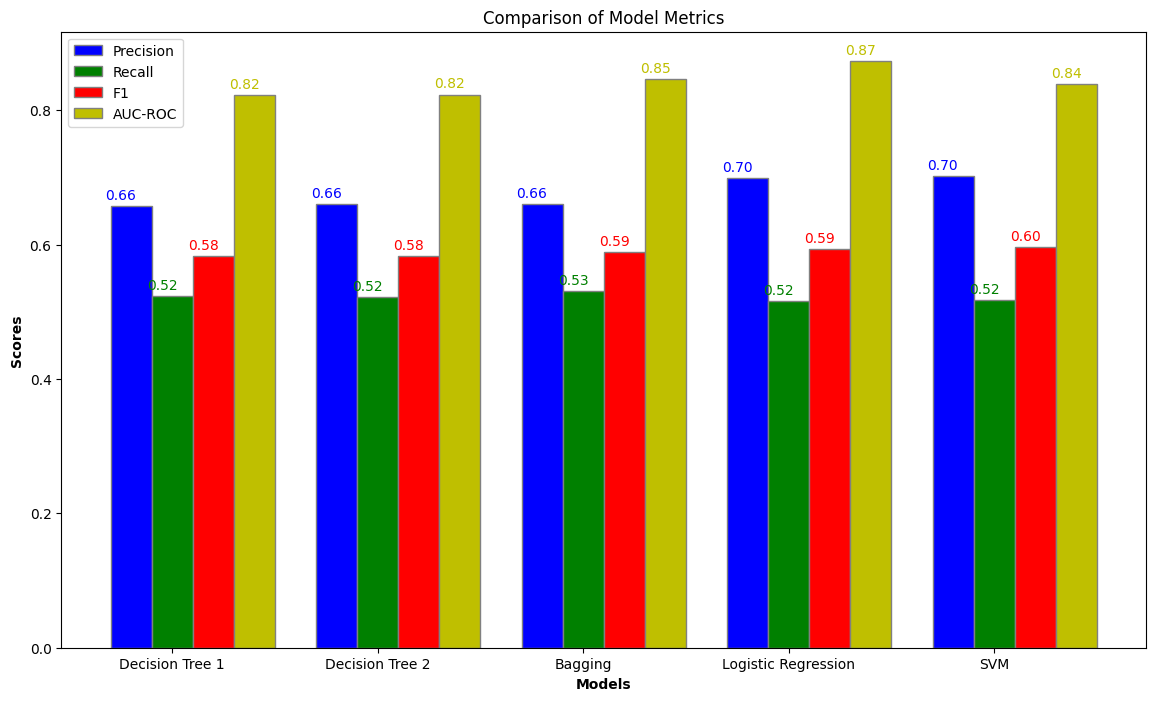

In [20]:
import numpy as np
import matplotlib.pyplot as plt

precisions = [precision_1, precision_2, precision_bagging, precision_lr, precision_svm]
recalls = [recall_1, recall_2, recall_bagging, recall_lr, recall_svm]
f1s = [f1_1, f1_2, f1_bagging, f1_lr, f1_svm]
auc_rocs = [roc_auc_1, roc_auc_2, roc_auc_bagging, roc_auc_lr, roc_auc_svm]

models = ['Decision Tree 1', 'Decision Tree 2', 'Bagging', 'Logistic Regression', 'SVM']

bar_width = 0.2

r1 = np.arange(len(models))
r2 = [x + bar_width for x in r1]
r3 = [x + bar_width for x in r2]
r4 = [x + bar_width for x in r3]

plt.figure(figsize=(14, 8))

plt.bar(r1, precisions, color='b', width=bar_width, edgecolor='grey', label='Precision')
plt.bar(r2, recalls, color='g', width=bar_width, edgecolor='grey', label='Recall')
plt.bar(r3, f1s, color='r', width=bar_width, edgecolor='grey', label='F1')
plt.bar(r4, auc_rocs, color='y', width=bar_width, edgecolor='grey', label='AUC-ROC')

plt.xlabel('Models', fontweight='bold')
plt.xticks([r + bar_width for r in range(len(models))], models)
plt.ylabel('Scores', fontweight='bold')
plt.title('Comparison of Model Metrics')

plt.legend()

for i in range(len(models)):
    plt.text(r1[i] - 0.05, precisions[i] + 0.01, f'{precisions[i]:.2f}', color='b', ha='center')
    plt.text(r2[i] - 0.05, recalls[i] + 0.01, f'{recalls[i]:.2f}', color='g', ha='center')
    plt.text(r3[i] - 0.05, f1s[i] + 0.01, f'{f1s[i]:.2f}', color='r', ha='center')
    plt.text(r4[i] - 0.05, auc_rocs[i] + 0.01, f'{auc_rocs[i]:.2f}', color='y', ha='center')

plt.show()

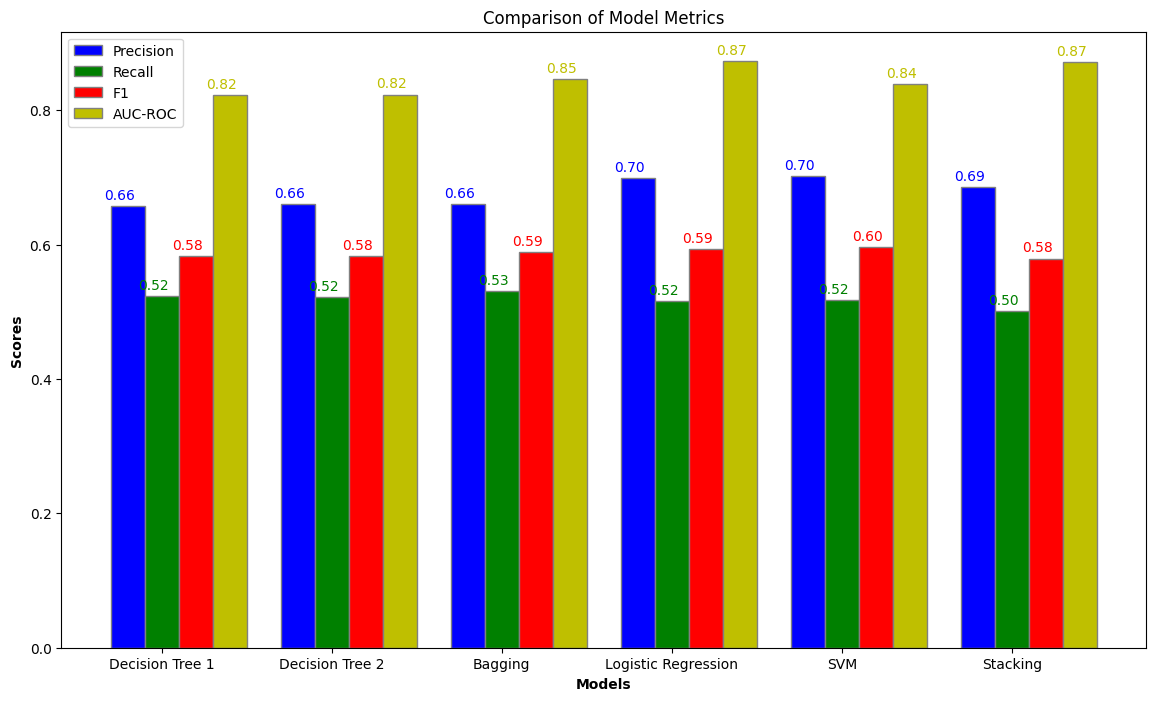

In [21]:
import numpy as np

import matplotlib.pyplot as plt

precisions = [precision_1, precision_2, precision_bagging, precision_lr, precision_svm, precision_stacking]
recalls = [recall_1, recall_2, recall_bagging, recall_lr, recall_svm, recall_stacking]
f1s = [f1_1, f1_2, f1_bagging, f1_lr, f1_svm, f1_stacking]
auc_rocs = [roc_auc_1, roc_auc_2, roc_auc_bagging, roc_auc_lr, roc_auc_svm, roc_auc_stacking]

models = ['Decision Tree 1', 'Decision Tree 2', 'Bagging', 'Logistic Regression', 'SVM', 'Stacking']

bar_width = 0.2

r1 = np.arange(len(models))
r2 = [x + bar_width for x in r1]
r3 = [x + bar_width for x in r2]
r4 = [x + bar_width for x in r3]

plt.figure(figsize=(14, 8))

plt.bar(r1, precisions, color='b', width=bar_width, edgecolor='grey', label='Precision')
plt.bar(r2, recalls, color='g', width=bar_width, edgecolor='grey', label='Recall')
plt.bar(r3, f1s, color='r', width=bar_width, edgecolor='grey', label='F1')
plt.bar(r4, auc_rocs, color='y', width=bar_width, edgecolor='grey', label='AUC-ROC')

plt.xlabel('Models', fontweight='bold')
plt.xticks([r + bar_width for r in range(len(models))], models)
plt.ylabel('Scores', fontweight='bold')
plt.title('Comparison of Model Metrics')

plt.legend()

for i in range(len(models)):
    plt.text(r1[i] - 0.05, precisions[i] + 0.01, f'{precisions[i]:.2f}', color='b', ha='center')
    plt.text(r2[i] - 0.05, recalls[i] + 0.01, f'{recalls[i]:.2f}', color='g', ha='center')
    plt.text(r3[i] - 0.05, f1s[i] + 0.01, f'{f1s[i]:.2f}', color='r', ha='center')
    plt.text(r4[i] - 0.05, auc_rocs[i] + 0.01, f'{auc_rocs[i]:.2f}', color='y', ha='center')

plt.show()

<font color='MediumOrchid'>**Your conclusions:**</font>
As the chart shows, plain logistic regression performed best 😭 — not even stacking.

**<font color='DarkOrange'>[0.25 points]</font>** Add the bagging model from before to the list of base models.
Train the new model and evaluate it

In [22]:
base_models_with_bagging = base_models + [('bagging', bagging_clf)]

stacking_clf_with_bagging = StackingClassifier(estimators=base_models_with_bagging, final_estimator=meta_model, cv=5)

stacking_clf_with_bagging.fit(X_train_2, y_train)

y_pred_stacking_with_bagging = stacking_clf_with_bagging.predict(X_test_2)
y_proba_stacking_with_bagging = stacking_clf_with_bagging.predict_proba(X_test_2)[:, 1]

precision_stacking_with_bagging = precision_score(y_test, y_pred_stacking_with_bagging)
recall_stacking_with_bagging = recall_score(y_test, y_pred_stacking_with_bagging)
f1_stacking_with_bagging = f1_score(y_test, y_pred_stacking_with_bagging)
roc_auc_stacking_with_bagging = roc_auc_score(y_test, y_proba_stacking_with_bagging)

print(f"Stacking with Bagging - Precision: {precision_stacking_with_bagging}, Recall: {recall_stacking_with_bagging}, F1: {f1_stacking_with_bagging}, AUC-ROC: {roc_auc_stacking_with_bagging}")

Stacking with Bagging - Precision: 0.6844827586206896, Recall: 0.5057324840764331, F1: 0.5816849816849817, AUC-ROC: 0.872727845465943


**<font color='DarkOrange'>[0.5 points]</font>** Try tuning the decision tree hyperparameters with `GridSearchCV`

Optimize `max_depth`, `min_samples_split` and `max_features` on the whole `X_train`

Did the decision tree improve on its own? And the whole stacking model?

In [23]:
# Пожалуй воздержусь, еще полчаса работы gridsearch-а

<font color='MediumOrchid'>**Your conclusions:**</font>

**<font color='DarkOrange'>[1 point]</font>**

Change the meta-model.
Try any other algorithm you have studied as the meta-model.

How did the quality change?

In [24]:
from sklearn.ensemble import StackingClassifier

base_models = [
    ('lr', LogisticRegression(random_state=42)),
    ('svm', SVC(random_state=42, probability=True)),
    ('dt', DecisionTreeClassifier(random_state=42))
]

meta_model = SVC(random_state=42, probability=True)

stacking_clf = StackingClassifier(estimators=base_models, final_estimator=meta_model, cv=5)

stacking_clf.fit(X_train_2, y_train)

y_pred_stacking = stacking_clf.predict(X_test_2)
y_proba_stacking = stacking_clf.predict_proba(X_test_2)[:, 1]

precision_stacking = precision_score(y_test, y_pred_stacking)
recall_stacking = recall_score(y_test, y_pred_stacking)
f1_stacking = f1_score(y_test, y_pred_stacking)
roc_auc_stacking = roc_auc_score(y_test, y_proba_stacking)

print(f"Stacking - Precision: {precision_stacking}, Recall: {recall_stacking}, F1: {f1_stacking}, AUC-ROC: {roc_auc_stacking}")

Stacking - Precision: 0.7056778679026651, Recall: 0.5171974522292994, F1: 0.5969125214408233, AUC-ROC: 0.7942970692389506


<font color='MediumOrchid'>**Your conclusions:**</font>
Ha, AUC-ROC is the lowest of all here, and the other metrics are the same as for the plain SVM — so not great.

**<font color='MediumSeaGreen'>[1 point, bonus]</font>** Tune the hyperparameters.

Also try tuning the hyperparameters of the linear regression and the new meta-model

Did the quality improve?

In [25]:
# Ваш код

<font color='MediumOrchid'>**Your conclusions:**</font>

## <font color='DarkOrange'>**Task 5 [1 point]**</font>

Draw conclusions about the models:

1. **<font color='DarkOrange'>[0.5 points]</font>** Which ensemble achieved the best metrics?

3. **<font color='DarkOrange'>[0.5 points]</font>** What are the advantages and disadvantages of each ensemble (bagging, stacking)?

In [26]:
# Ваш код

<font color='MediumOrchid'>**Your conclusions:**</font>

## <font color='MediumSeaGreen'>**Bonus [0.5 points]**</font>

Write down your favourite film / cartoon / TV series / etc.

<font color='MediumOrchid'>**Your conclusions:**</font> The Hitchhiker's Guide to the Galaxy 😎